<a href="https://colab.research.google.com/github/harpreetsingh171190-cmyk/serverlog-intelligence-analytics/blob/main/ServerLog_Intelligence_Analytics_Colab_Embedded_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ServerLog Intelligence — Security & Performance Analytics

**Portfolio-grade, Google Colab project** for multi-format server-log parsing, traffic and error analysis, defensive security indicators, period comparisons, interactive-style visual analytics, 3D visualization, historical SQLite snapshots, and downloadable HTML/PDF reports.

## Project purpose
Modern applications produce large volumes of server logs. Manually inspecting them makes it difficult to identify traffic spikes, recurring errors, slow endpoints, suspicious request patterns, and changes over time. This project turns supported logs into measurable operational insights and a shareable report.

## What this notebook produces
- Data-quality summary and normalized request table
- KPI cards/table: requests, unique IPs, error rate, server errors, and latency
- HTTP status distribution, endpoint error rates, latency and traffic charts
- Today vs. yesterday and this week vs. last week comparison tables (when timestamps cover those periods)
- Defensive indicators for suspicious paths, repeated 401/403 responses, and 404 scanning (heuristics only)
- 3D traffic visualization where timestamp and response-time data are available
- SQLite daily history and monthly trend chart
- Downloadable HTML report, optional PDF report, and a generated `README.md`

**Important:** Detection is heuristic, not proof of compromise. IP geolocation is not required. Do not upload secrets, tokens, personal data, or sensitive production logs to a public notebook. Use synthetic or sanitized logs for a public portfolio.

### Supported input formats
CSV; JSON/JSONL; common Apache/Nginx access logs; syslog/auth.log; common Cloudflare JSON/CSV exports; and common AWS CloudTrail JSON event files. Vendor schemas vary, so review the normalized output and data-quality notes after loading.

In [1]:
# Install lightweight dependencies used by the notebook.
%pip -q install pandas matplotlib seaborn reportlab

## 1. Load logs

The sample `sample_server_logs.csv` dataset is embedded directly in the notebook. Run cells from top to bottom; no manual upload or `load_log_file` helper is required.


In [2]:
# The sample_server_logs.csv dataset is embedded in this notebook as Base64.
# No upload dialog or separate CSV file is needed: run this cell directly.
import base64
_EMBEDDED_SAMPLE_CSV_B64 = """
...
"""

# Imports and schema normalization are intentionally self-contained so this cell
# works when run in a fresh Colab runtime, without relying on earlier variables.
from io import BytesIO
from pathlib import Path
from datetime import datetime, date, timezone, timedelta
import sqlite3
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

_sample_csv_bytes = base64.b64decode("".join(_EMBEDDED_SAMPLE_CSV_B64.split()))
df_raw = pd.read_csv(BytesIO(_sample_csv_bytes))
REQUIRED_COLUMNS = ["timestamp", "ip", "method", "path", "status_code", "response_time_ms", "user_agent"]
for c in REQUIRED_COLUMNS:
    if c not in df_raw.columns:
        df_raw[c] = np.nan if c in ["status_code", "response_time_ms"] else "unknown"
print(f"Loaded embedded dataset: sample_server_logs.csv ({len(df_raw):,} rows)")
if df_raw.empty:
    raise ValueError("The embedded sample dataset is empty or could not be parsed.")

df = df_raw.copy()
df["timestamp_parsed"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)
df["status_code"] = pd.to_numeric(df["status_code"], errors="coerce")
df["response_time_ms"] = pd.to_numeric(df["response_time_ms"], errors="coerce")
df["ip"] = df["ip"].fillna("unknown").astype(str)
df["path"] = df["path"].fillna("unknown").astype(str)
df["method"] = df["method"].fillna("UNKNOWN").astype(str)
df["status_class"] = df["status_code"].apply(lambda x: f"{int(x)//100}xx" if pd.notna(x) and 100 <= x < 600 else "Non-HTTP/Unknown")
df["date"] = df["timestamp_parsed"].dt.date
print(f"Parsed rows: {len(df):,} | Valid timestamps: {df['timestamp_parsed'].notna().sum():,}")
display(df.head(10))

Loaded embedded dataset: sample_server_logs.csv (1,000 rows)
Parsed rows: 1,000 | Valid timestamps: 1,000


,timestamp,ip,method,path,status_code,response_time_ms,user_agent,timestamp_parsed,status_class,date
0,2026-10-01 00:44:46,192.168.1.20,POST,/,301,71,curl/8.5.0,2026-10-01 00:44:46+00:00,3xx,2026-10-01
1,2026-10-01 01:16:47,192.168.1.28,HEAD,/api/users,200,35,python-requests/2.32.0,2026-10-01 01:16:47+00:00,2xx,2026-10-01
2,2026-10-01 03:33:24,192.168.1.35,GET,/index.html,200,68,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,2026-10-01 03:33:24+00:00,2xx,2026-10-01
3,2026-10-01 04:16:13,192.168.1.23,GET,/assets/app.css,201,100,Googlebot/2.1 (+http://www.google.com/bot.html),2026-10-01 04:16:13+00:00,2xx,2026-10-01
4,2026-10-01 04:38:32,192.168.1.29,GET,/api/users,200,51,Googlebot/2.1 (+http://www.google.com/bot.html),2026-10-01 04:38:32+00:00,2xx,2026-10-01
5,2026-10-01 04:41:48,192.168.1.37,HEAD,/assets/logo.png,200,100,Googlebot/2.1 (+http://www.google.com/bot.html),2026-10-01 04:41:48+00:00,2xx,2026-10-01
6,2026-10-01 04:54:15,192.168.1.16,GET,/,200,65,Mozilla/5.0 (Macintosh; Intel Mac OS X 14_0) A...,2026-10-01 04:54:15+00:00,2xx,2026-10-01
7,2026-10-01 05:12:07,192.168.1.40,PUT,/missing-page,400,46,Googlebot/2.1 (+http://www.google.com/bot.html),2026-10-01 05:12:07+00:00,4xx,2026-10-01
8,2026-10-01 05:25:35,192.168.1.14,PUT,/api/products,503,130,python-requests/2.32.0,2026-10-01 05:25:35+00:00,5xx,2026-10-01
9,2026-10-01 05:34:57,203.0.113.1,GET,/api/orders,401,230,python-requests/2.32.0,2026-10-01 05:34:57+00:00,4xx,2026-10-01


## 2. Data quality and headline KPIs

In [3]:
http = df[df["status_code"].between(100,599)]
errors = http[http["status_code"] >= 400]
server_errors = http[http["status_code"] >= 500]
kpis = pd.DataFrame({"Metric":["Total records","HTTP records","Unique client IPs","HTTP error rate (%)","5xx server errors","Mean response time (ms)","P95 response time (ms)","Valid timestamps (%)"],"Value":[len(df),len(http),df.loc[df.ip.ne("unknown"),"ip"].nunique(),round(100*len(errors)/len(http),2) if len(http) else np.nan,len(server_errors),round(http.response_time_ms.mean(),2),round(http.response_time_ms.quantile(.95),2),round(100*df.timestamp_parsed.notna().mean(),2)]})
display(kpis)
quality=pd.DataFrame({"Check":["Missing/invalid timestamps","Unknown IP values","Missing HTTP status","Missing response time","Duplicate normalized rows"],"Count":[df.timestamp_parsed.isna().sum(),df.ip.eq("unknown").sum(),df.status_code.isna().sum(),df.response_time_ms.isna().sum(),df.duplicated(subset=["timestamp","ip","method","path","status_code"]).sum()]})
display(quality)

,Metric,Value
0,Total records,1000.00
1,HTTP records,1000.00
2,Unique client IPs,49.00
3,HTTP error rate (%),26.50
4,5xx server errors,76.00
5,Mean response time (ms),101.11
6,P95 response time (ms),272.20
7,Valid timestamps (%),100.00


,Check,Count
0,Missing/invalid timestamps,0
1,Unknown IP values,0
2,Missing HTTP status,0
3,Missing response time,0
4,Duplicate normalized rows,0


## 3. HTTP status distribution and endpoint comparison

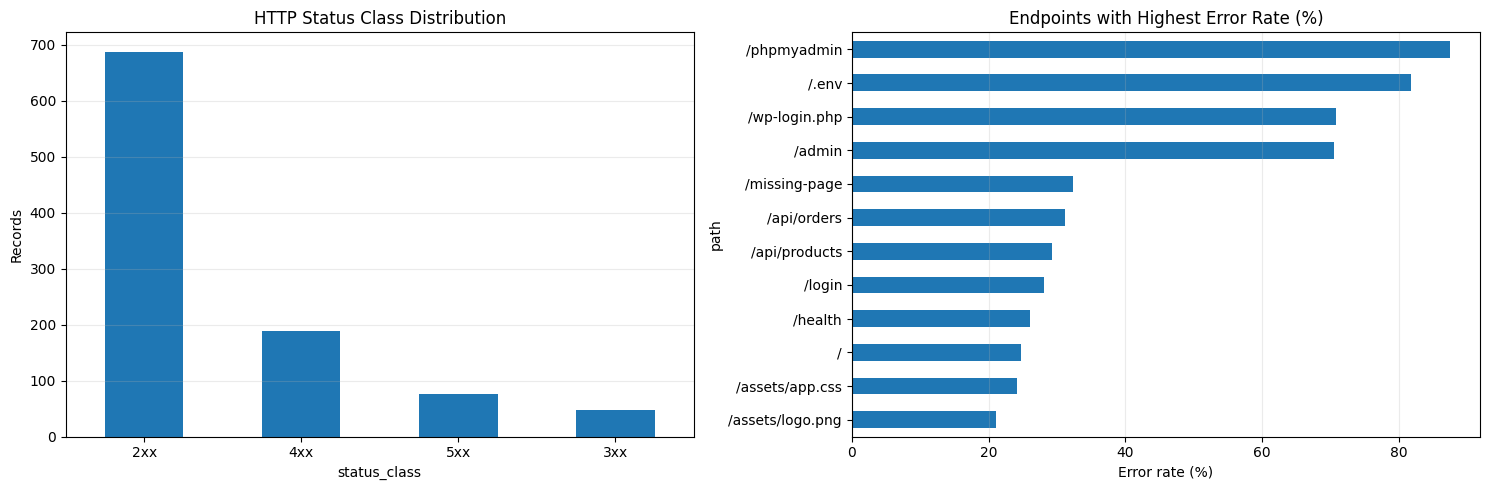

,path,requests,errors,mean_latency_ms,error_rate_pct
0,/phpmyadmin,8,7,375.750000,87.50
1,/.env,11,9,593.454545,81.82
2,/wp-login.php,24,17,400.541667,70.83
3,/admin,17,12,240.705882,70.59
4,/missing-page,34,11,73.764706,32.35
5,/api/orders,45,14,77.577778,31.11
6,/api/products,82,24,79.256098,29.27
7,/login,89,25,80.202247,28.09
8,/health,50,13,66.820000,26.00
9,/,158,39,83.746835,24.68


In [4]:
fig, axes = plt.subplots(1,2,figsize=(15,5))
df.status_class.value_counts().plot(kind="bar",ax=axes[0],title="HTTP Status Class Distribution",rot=0)
axes[0].set_ylabel("Records"); axes[0].grid(axis="y",alpha=.25)
if len(http):
    endpoint=http.groupby("path").agg(requests=("path","size"), errors=("status_code",lambda x:(x>=400).sum()), mean_latency_ms=("response_time_ms","mean"))
    endpoint["error_rate_pct"]=(endpoint.errors/endpoint.requests*100).round(2)
    endpoint=endpoint.sort_values(["error_rate_pct","requests"],ascending=False).head(12)
    endpoint.error_rate_pct.sort_values().plot(kind="barh",ax=axes[1],title="Endpoints with Highest Error Rate (%)")
    axes[1].set_xlabel("Error rate (%)"); axes[1].grid(axis="x",alpha=.25)
else:
    endpoint=pd.DataFrame(); axes[1].text(.1,.5,"No HTTP status codes detected",transform=axes[1].transAxes)
plt.tight_layout(); plt.show()
display(endpoint.reset_index() if len(endpoint) else endpoint)

## 4. Traffic and latency over time

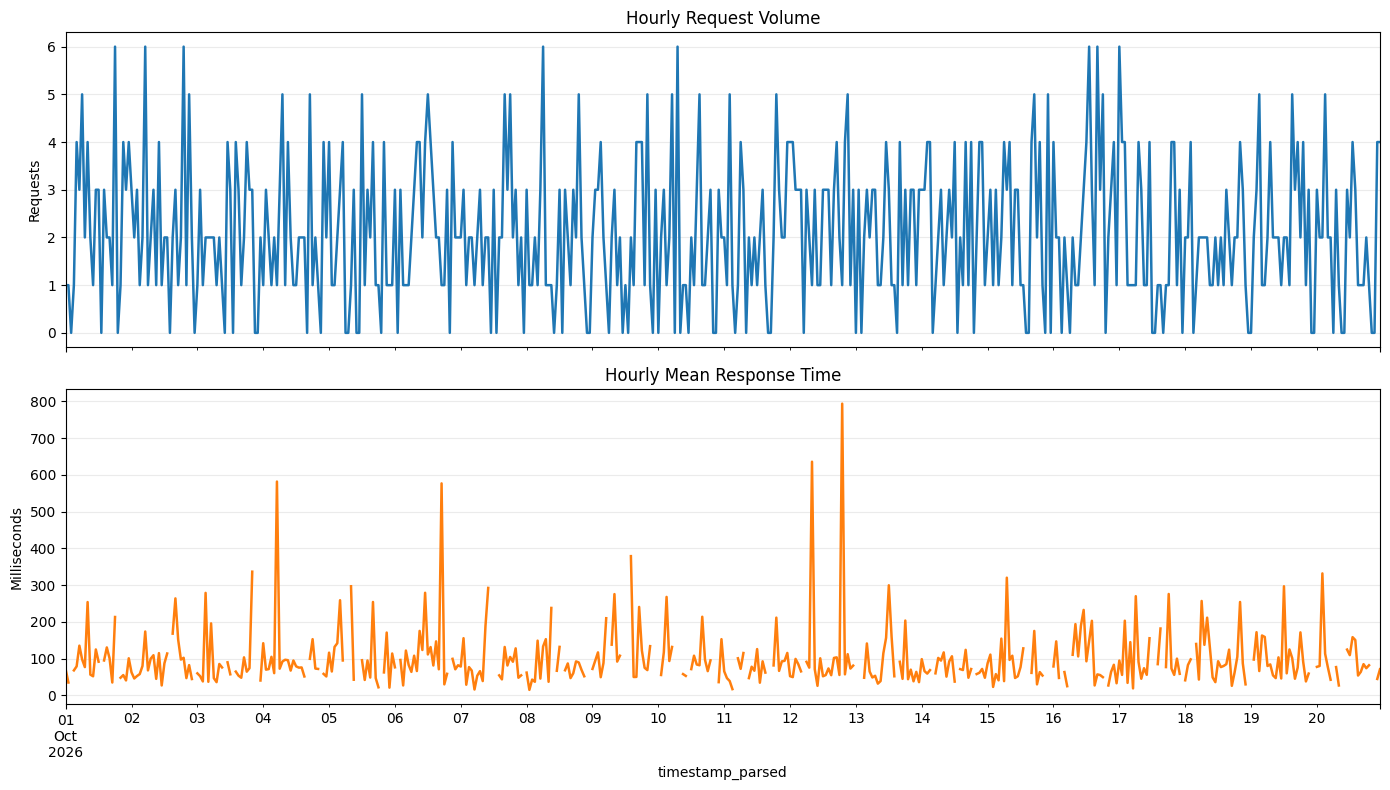

,requests,mean_latency_ms,errors
timestamp_parsed,,,
2026-10-20 00:00:00+00:00,3,77.666667,0
2026-10-20 01:00:00+00:00,2,80.000000,2
2026-10-20 02:00:00+00:00,2,332.000000,1
2026-10-20 03:00:00+00:00,5,113.400000,1
2026-10-20 04:00:00+00:00,2,76.500000,1
2026-10-20 05:00:00+00:00,2,42.500000,0
2026-10-20 06:00:00+00:00,0,NaN,0
2026-10-20 07:00:00+00:00,3,77.000000,0
2026-10-20 08:00:00+00:00,1,27.000000,0


In [5]:
timed=df.dropna(subset=["timestamp_parsed"]).sort_values("timestamp_parsed")
if not timed.empty:
    hourly=timed.set_index("timestamp_parsed").resample("1h").agg(requests=("ip","size"), mean_latency_ms=("response_time_ms","mean"), errors=("status_code",lambda x:(x>=400).sum()))
    fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True)
    hourly.requests.plot(ax=axes[0],title="Hourly Request Volume",lw=1.8); axes[0].set_ylabel("Requests"); axes[0].grid(alpha=.25)
    hourly.mean_latency_ms.plot(ax=axes[1],title="Hourly Mean Response Time",color="tab:orange",lw=1.8); axes[1].set_ylabel("Milliseconds"); axes[1].grid(alpha=.25)
    plt.tight_layout(); plt.show(); display(hourly.tail(24))
else:
    hourly=pd.DataFrame(); print("No parseable timestamps; time-series charts are unavailable for this file.")

## 5. Period-over-period comparison

In [6]:
def period_metrics(frame, label):
    h=frame[frame.status_code.between(100,599)]
    return {"Period":label,"Requests":len(frame),"Unique IPs":frame.loc[frame.ip.ne("unknown"),"ip"].nunique(),"Error rate (%)":round(100*(h.status_code>=400).mean(),2) if len(h) else np.nan,"5xx errors":int((h.status_code>=500).sum()),"Mean latency (ms)":round(h.response_time_ms.mean(),2),"P95 latency (ms)":round(h.response_time_ms.quantile(.95),2)}
comparison=[]
if timed.empty:
    print("Period comparison unavailable because timestamps could not be parsed.")
else:
    max_date=timed.timestamp_parsed.max().date(); today_start=pd.Timestamp(max_date,tz="UTC"); tomorrow=today_start+pd.Timedelta(days=1); yesterday_start=today_start-pd.Timedelta(days=1)
    today_df=df[(df.timestamp_parsed>=today_start)&(df.timestamp_parsed<tomorrow)]
    yesterday_df=df[(df.timestamp_parsed>=yesterday_start)&(df.timestamp_parsed<today_start)]
    comparison += [period_metrics(today_df,f"Latest date ({max_date})"),period_metrics(yesterday_df,f"Previous date ({max_date-timedelta(days=1)})")]
    week_start=today_start-pd.Timedelta(days=today_start.weekday()); prev_week_start=week_start-pd.Timedelta(days=7)
    this_week=df[(df.timestamp_parsed>=week_start)&(df.timestamp_parsed<week_start+pd.Timedelta(days=7))]
    prev_week=df[(df.timestamp_parsed>=prev_week_start)&(df.timestamp_parsed<week_start)]
    comparison += [period_metrics(this_week,"Current week to date"),period_metrics(prev_week,"Previous full week")]
    comparison_df=pd.DataFrame(comparison); display(comparison_df)
    print("Note: periods are based on the latest date in the uploaded data, in UTC, to make comparisons reproducible.")

,Period,Requests,Unique IPs,Error rate (%),5xx errors,Mean latency (ms),P95 latency (ms)
0,Latest date (2026-10-20),46,31,26.09,5,102.09,268.0
1,Previous date (2026-10-19),52,33,34.62,4,96.71,288.6
2,Current week to date,98,44,30.61,9,99.23,280.2
3,Previous full week,365,49,25.75,22,97.45,269.2


Note: periods are based on the latest date in the uploaded data, in UTC, to make comparisons reproducible.


## 6. Defensive security indicators (heuristics, not verdicts)

In [7]:
suspicious_terms=["/.env","/wp-login","/phpmyadmin","/admin","/etc/passwd","../","/cgi-bin"]
df["suspicious_path_indicator"]=df.path.str.lower().apply(lambda p:any(term in p for term in suspicious_terms))
failed_auth=df[df.status_code.isin([401,403])].groupby("ip").size().sort_values(ascending=False).rename("401_403_count")
not_found=df[df.status_code.eq(404)].groupby("ip").agg({"path":["size","nunique"]})
not_found.columns=["404_count","unique_404_paths"]
not_found=not_found.sort_values(["404_count","unique_404_paths"],ascending=False)
indicators=pd.DataFrame({"Indicator":["Requests matching sensitive-path patterns","IPs with 5+ 401/403 responses","IPs with 10+ 404 responses and 5+ unique paths"],"Count":[int(df.suspicious_path_indicator.sum()),int((failed_auth>=5).sum()),int(((not_found.get('404_count',pd.Series(dtype=int))>=10)&(not_found.get('unique_404_paths',pd.Series(dtype=int))>=5)).sum())]})
display(indicators)
print("Sensitive-path examples:"); display(df.loc[df.suspicious_path_indicator,["timestamp","ip","method","path","status_code"]].head(20))
print("Repeated authentication failures:"); display(failed_auth.head(10).to_frame())
print("404 scanning candidates:"); display(not_found[(not_found["404_count"]>=10)&(not_found["unique_404_paths"]>=5)].head(10) if not not_found.empty else not_found)

,Indicator,Count
0,Requests matching sensitive-path patterns,60
1,IPs with 5+ 401/403 responses,0
2,IPs with 10+ 404 responses and 5+ unique paths,0


Sensitive-path examples:


,timestamp,ip,method,path,status_code
42,2026-10-01 18:46:04,192.168.1.11,POST,/.env,200
70,2026-10-02 05:37:31,192.168.1.29,DELETE,/admin,200
92,2026-10-02 16:17:16,192.168.1.41,HEAD,/phpmyadmin,404
117,2026-10-03 03:41:11,192.168.1.10,DELETE,/phpmyadmin,401
146,2026-10-03 18:27:38,203.0.113.2,POST,/phpmyadmin,404
152,2026-10-03 20:22:56,203.0.113.3,GET,/admin,404
166,2026-10-04 05:40:32,203.0.113.4,DELETE,/wp-login.php,200
170,2026-10-04 07:01:18,192.168.1.21,PUT,/admin,200
171,2026-10-04 07:17:27,192.168.1.16,PUT,/admin,403
176,2026-10-04 09:06:36,203.0.113.2,HEAD,/admin,404


Repeated authentication failures:


,401_403_count
ip,
192.168.1.14,4
192.168.1.15,4
192.168.1.13,3
192.168.1.10,3
203.0.113.11,3
192.168.1.16,3
203.0.113.1,3
192.168.1.42,3
203.0.113.2,2


404 scanning candidates:


,404_count,unique_404_paths
ip,,


## 7. 3D traffic visualization

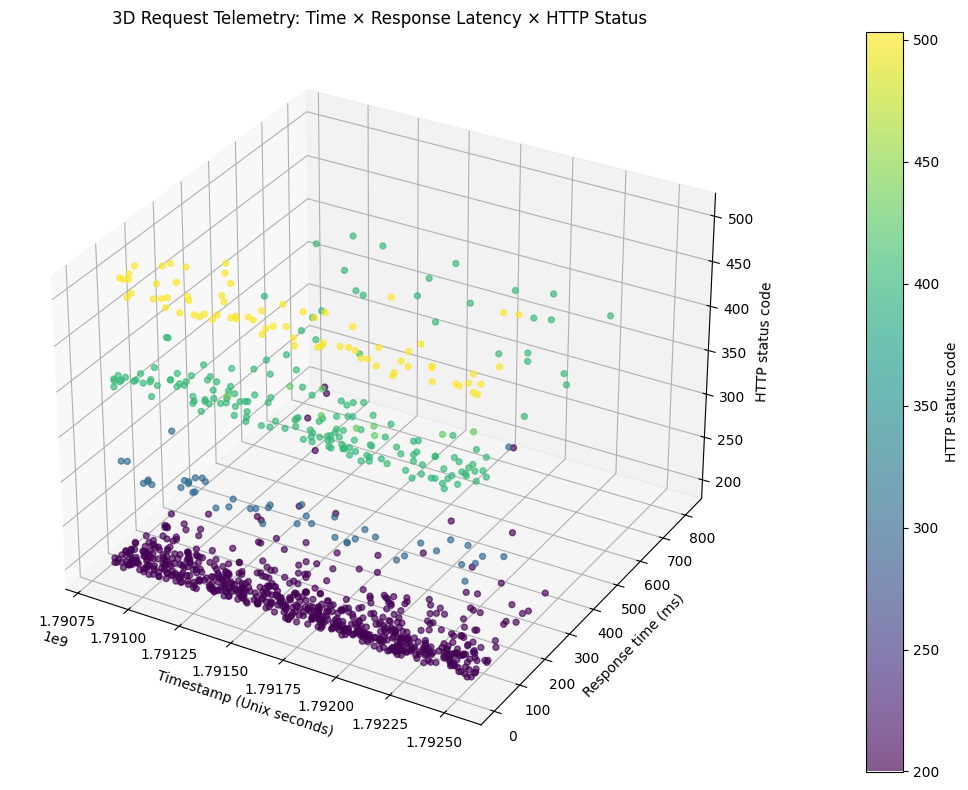

In [8]:
# 3D plot maps time, response latency, and HTTP status. Missing dimensions are excluded.
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
plot3=df.dropna(subset=["timestamp_parsed","response_time_ms","status_code"]).copy()
if len(plot3)>1200: plot3=plot3.sample(1200,random_state=42)
if len(plot3)>=3:
    x=(plot3.timestamp_parsed.astype("int64")/1e9).to_numpy()
    y=plot3.response_time_ms.to_numpy(); z=plot3.status_code.to_numpy()
    fig=plt.figure(figsize=(12,8)); ax=fig.add_subplot(111,projection="3d")
    sc=ax.scatter(x,y,z,c=z,cmap="viridis",alpha=.65,s=18)
    ax.set_title("3D Request Telemetry: Time × Response Latency × HTTP Status")
    ax.set_xlabel("Timestamp (Unix seconds)"); ax.set_ylabel("Response time (ms)"); ax.set_zlabel("HTTP status code")
    fig.colorbar(sc,ax=ax,pad=.1,label="HTTP status code"); plt.tight_layout(); plt.show()
else:
    print("3D chart skipped: need at least 3 rows with valid timestamp, latency, and HTTP status fields. Some log formats do not include latency.")

## 8. SQLite history and monthly trends

,snapshot_date,dataset_name,total_records,unique_ips,error_rate_pct,server_errors,mean_latency_ms,p95_latency_ms
0,2026-10-20,uploaded_dataset,1000,49,26.5,76,101.106,272.2


/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:1567: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)
/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:1567: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)
/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:1567: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


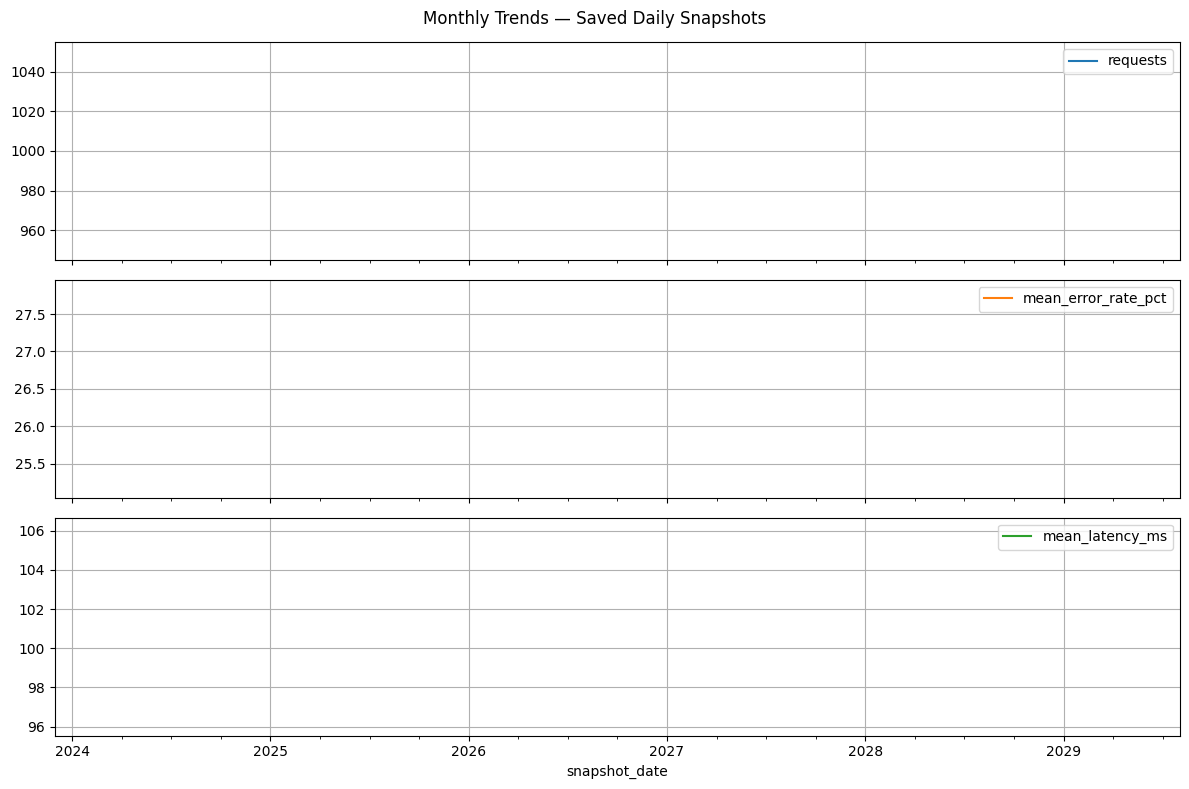

Database path: /content/server_log_history.sqlite3
Colab sessions may reset. Download the SQLite file or save it to mounted Google Drive for persistence.


In [9]:
DB_PATH=Path("server_log_history.sqlite3")
with sqlite3.connect(DB_PATH) as conn:
    conn.execute("""CREATE TABLE IF NOT EXISTS daily_snapshots (
        snapshot_date TEXT NOT NULL, dataset_name TEXT NOT NULL, total_records INTEGER,
        unique_ips INTEGER, error_rate_pct REAL, server_errors INTEGER,
        mean_latency_ms REAL, p95_latency_ms REAL, PRIMARY KEY(snapshot_date,dataset_name))""")
    latest=(timed.timestamp_parsed.max().date().isoformat() if not timed.empty else date.today().isoformat())
    row=(latest,"uploaded_dataset",len(df),int(df.loc[df.ip.ne('unknown'),'ip'].nunique()),float(kpis.loc[kpis.Metric.eq('HTTP error rate (%)'),'Value'].iloc[0]) if pd.notna(kpis.loc[kpis.Metric.eq('HTTP error rate (%)'),'Value'].iloc[0]) else None,int(len(server_errors)),float(http.response_time_ms.mean()) if http.response_time_ms.notna().any() else None,float(http.response_time_ms.quantile(.95)) if http.response_time_ms.notna().any() else None)
    conn.execute("INSERT OR REPLACE INTO daily_snapshots VALUES (?,?,?,?,?,?,?,?)",row); conn.commit()
    history=pd.read_sql_query("SELECT * FROM daily_snapshots ORDER BY snapshot_date",conn)
display(history)
if len(history):
    history["snapshot_date"]=pd.to_datetime(history.snapshot_date,errors="coerce")
    monthly=history.set_index("snapshot_date").resample("MS").agg(requests=("total_records","sum"),mean_error_rate_pct=("error_rate_pct","mean"),mean_latency_ms=("mean_latency_ms","mean"))
    if len(monthly):
        monthly[["requests","mean_error_rate_pct","mean_latency_ms"]].plot(subplots=True,figsize=(12,8),title="Monthly Trends — Saved Daily Snapshots",grid=True); plt.tight_layout(); plt.show()
print("Database path:", DB_PATH.resolve())
print("Colab sessions may reset. Download the SQLite file or save it to mounted Google Drive for persistence.")

## 9. Generate shareable HTML and PDF reports

In [10]:
from datetime import timezone
REPORT_DIR=Path("server_log_reports"); REPORT_DIR.mkdir(exist_ok=True)
created=datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
# Create compact tables for the report.
def table_html(frame, title, max_rows=30):
    if frame is None or len(frame)==0: return f"<h2>{html.escape(title)}</h2><p>No data available.</p>"
    return f"<h2>{html.escape(title)}</h2>"+frame.head(max_rows).to_html(index=False, escape=True, border=0, classes="data")
report_html=f"""<!doctype html><html><head><meta charset='utf-8'><title>ServerLog Intelligence Report</title>
<style>body{{font-family:Arial,sans-serif;max-width:1100px;margin:32px auto;padding:0 18px;color:#182230}}h1{{color:#123b5d}}h2{{margin-top:28px;color:#145a78}}.note{{background:#eef6fa;padding:12px;border-left:4px solid #2b7a9b}}table.data{{border-collapse:collapse;width:100%;font-size:13px}}.data th,.data td{{border:1px solid #d7e0e7;padding:7px;text-align:left}}.data th{{background:#eaf1f5}}img{{max-width:100%;height:auto}}footer{{margin-top:32px;color:#667}}</style></head><body>
<h1>ServerLog Intelligence — Analysis Report</h1><p>Generated: {created}</p>
<p class='note'>This report provides operational analytics and heuristic security indicators. Indicators are not proof of malicious activity. Confirm findings with system owners and additional evidence.</p>
<h2>Project purpose</h2><p>Normalize server and security logs into a common view to help teams understand traffic, errors, latency, and suspicious request patterns, then compare periods and preserve daily summaries.</p>
{table_html(kpis,'Headline KPIs')}{table_html(quality,'Data Quality')}{table_html(endpoint.reset_index() if len(endpoint) else endpoint,'Endpoint Error Analysis')}
{table_html(comparison_df if 'comparison_df' in globals() else pd.DataFrame(),'Period-over-Period Comparison')}
{table_html(indicators,'Security Indicators')}{table_html(failed_auth.head(20).reset_index() if len(failed_auth) else pd.DataFrame(),'Authentication Failure Candidates')}
<p>Source records parsed: {len(df):,}. Unique IPs: {df.loc[df.ip.ne('unknown'),'ip'].nunique():,}.</p><footer>Generated by the ServerLog Intelligence Colab notebook.</footer></body></html>"""
html_path=REPORT_DIR/"server_log_analysis_report.html"; html_path.write_text(report_html,encoding="utf-8")
print("HTML report created:",html_path)
try:
    from reportlab.lib import colors
    from reportlab.lib.pagesizes import A4, landscape
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, PageBreak
    from reportlab.lib.styles import getSampleStyleSheet
    from reportlab.lib.units import mm
    pdf_path=REPORT_DIR/"server_log_analysis_report.pdf"
    styles=getSampleStyleSheet(); story=[Paragraph("ServerLog Intelligence — Analysis Report",styles["Title"]),Paragraph(f"Generated: {created}",styles["Normal"]),Spacer(1,6*mm),Paragraph("Purpose: normalize server logs to analyze traffic, errors, latency, period changes, and heuristic security indicators.",styles["BodyText"]),Spacer(1,5*mm)]
    def add_pdf_table(frame,title):
        story.append(Paragraph(title,styles["Heading2"]))
        if frame is None or frame.empty: story.append(Paragraph("No data available.",styles["BodyText"])); return
        dat=[list(map(str,frame.columns))]+frame.head(20).fillna("").astype(str).values.tolist()
        t=Table(dat,repeatRows=1,hAlign="LEFT")
        t.setStyle(TableStyle([("BACKGROUND",(0,0),(-1,0),colors.HexColor('#dceaf2')),("GRID",(0,0),(-1,-1),.35,colors.grey),("FONTSIZE",(0,0),(-1,-1),7),("VALIGN",(0,0),(-1,-1),"TOP"),("ROWBACKGROUNDS",(0,1),(-1,-1),[colors.white,colors.HexColor('#f5f8fa')])]))
        story.append(t); story.append(Spacer(1,4*mm))
    add_pdf_table(kpis,"Headline KPIs"); add_pdf_table(quality,"Data Quality"); add_pdf_table(endpoint.reset_index() if len(endpoint) else endpoint,"Endpoint Errors"); add_pdf_table(comparison_df if 'comparison_df' in globals() else pd.DataFrame(),"Period Comparison"); add_pdf_table(indicators,"Security Indicators")
    story.append(Paragraph("Security indicators are heuristic signals, not proof of compromise. Validate findings before taking action.",styles["Italic"]))
    SimpleDocTemplate(str(pdf_path),pagesize=landscape(A4),rightMargin=12*mm,leftMargin=12*mm,topMargin=12*mm,bottomMargin=12*mm).build(story)
    print("PDF report created:",pdf_path)
except Exception as e:
    pdf_path=None; print("PDF generation unavailable:",e,"HTML report is still available.")
display(FileLink(str(html_path)))
if pdf_path and Path(pdf_path).exists(): display(FileLink(str(pdf_path)))

HTML report created: server_log_reports/server_log_analysis_report.html
PDF report created: server_log_reports/server_log_analysis_report.pdf


/content/server_log_reports/server_log_analysis_report.html

/content/server_log_reports/server_log_analysis_report.pdf

## 10. Generate and download the GitHub README.md

In [11]:
README = r"""# ServerLog Intelligence — Security & Performance Analytics

A Google Colab-based server-log analytics project that normalizes common log formats and produces operational KPIs, period comparisons, charts, 3D telemetry visualization, heuristic security indicators, SQLite history, and shareable HTML/PDF reports.

## Why this project?
Server logs are often distributed across different formats and contain too much detail for quick manual review. This project provides a repeatable workflow to summarize request volume, identify error-heavy endpoints, inspect latency, compare time periods, and highlight suspicious patterns for further investigation.

## Key features
- Multi-format input: CSV, JSON/JSONL, common Apache/Nginx access logs, syslog/auth.log, and best-effort Cloudflare/AWS JSON mappings.
- Data-quality checks and normalized request records.
- KPIs: request volume, unique IPs, HTTP error rate, 5xx errors, mean latency, and p95 latency.
- HTTP status distribution, endpoint error comparison, traffic and latency time series.
- Latest date vs previous date and current week-to-date vs previous full week comparisons.
- Heuristic indicators for sensitive-path probing, repeated 401/403 responses, and 404 scanning.
- 3D visualization of timestamp, latency, and HTTP status when fields are available.
- SQLite daily snapshots and monthly trend plots.
- Exportable HTML and PDF reports.

## Run in Google Colab
1. Upload `ServerLog_Intelligence_Analytics_Colab.ipynb` to Google Colab.
2. Run cells from top to bottom.
3. Upload a sanitized `.csv`, `.json`, `.jsonl`, `.log`, or `.txt` log file when prompted. If no file is uploaded, synthetic demonstration data is used.
4. Review the normalized data, KPIs, comparison tables, charts, and security indicators.
5. Download the generated HTML/PDF reports, SQLite database, and this README as needed.

## Example input fields
The parser attempts to map common names for timestamp, IP/client address, HTTP method, path/URL, status code, response time, and user agent. Not all formats include every field; for example, syslog and CloudTrail events may not have HTTP status or response latency.

## Repository structure
```text
ServerLog_Intelligence_Analytics_Colab.ipynb
README.md
screenshots/       # Add screenshots of actual notebook outputs
sample_logs/       # Add sanitized sample data only
reports/           # Optional example reports; avoid committing sensitive data
```

## Limitations and responsible use
- Format mapping is best-effort because AWS and Cloudflare schemas vary by product and export configuration.
- Security indicators are heuristics and may produce false positives; they do not establish that an IP is malicious or a server is compromised.
- IP geolocation and reputation checks are intentionally not required by this notebook.
- Period comparisons use UTC and the latest date present in the uploaded dataset. Meaningful comparisons require data for both periods.
- SQLite storage in a Colab runtime is temporary unless the database is downloaded or saved to persistent storage such as Google Drive.
- Do not upload secrets, credentials, personal information, or unredacted production logs to public repositories or shared notebooks.

## Technology stack
Python, Pandas, NumPy, Matplotlib, SQLite, ReportLab, and Google Colab.

## Future improvements
Schema-specific CloudTrail/Cloudflare adapters, automated tests, richer anomaly detection, dashboard deployment, and scheduled collection can be added as separate extensions.

## License
Choose a license before publishing (for example, MIT if you want to permit reuse with attribution).

## Author
Add your name, portfolio, and LinkedIn/GitHub profile here.
"""
readme_path=Path("README.md"); readme_path.write_text(README,encoding="utf-8")
print("README created:",readme_path.resolve())
display(FileLink(str(readme_path)))
try:
    from google.colab import files
    files.download(str(readme_path))
except Exception:
    print("Outside Google Colab: use the README.md link above to download the file.")

README created: /content/README.md


/content/README.md

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Download persistent artifacts

In [12]:
# Download the SQLite database so history survives a temporary Colab session.
print("Available artifacts:")
for artifact in [DB_PATH, html_path, pdf_path if 'pdf_path' in globals() else None, Path("README.md")]:
    if artifact and Path(artifact).exists(): print("-",Path(artifact).resolve())
try:
    from google.colab import files
    if DB_PATH.exists(): files.download(str(DB_PATH))
except Exception:
    pass

Available artifacts:
- /content/server_log_history.sqlite3
- /content/server_log_reports/server_log_analysis_report.html
- /content/server_log_reports/server_log_analysis_report.pdf
- /content/README.md


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:


from google.colab import files
from pathlib import Path

# Find an already-uploaded Markdown file first
candidates = sorted(
    Path("/content").glob("*.md"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if candidates:
    readme_path = candidates[0]
    print(f"Using existing file: {readme_path.name}")
else:
    print("Please upload your README.md file")
    uploaded = files.upload()

    md_files = [
        name for name in uploaded
        if name.lower().endswith(".md")
    ]

    if not md_files:
        raise FileNotFoundError("No Markdown (.md) file was uploaded.")

    readme_path = Path("/content") / md_files[0]

readme = readme_path.read_text(encoding="utf-8")

diagrams = r"""
<!-- SERVERLOG_DIAGRAMS_START -->

## System Architecture

```mermaid
flowchart TD
    A["CSV / JSON / JSONL / Server Logs"] --> B["Log Parsing"]
    B --> C["Validation and Normalization"]
    C --> D["Analytics Engine"]
    D --> E["KPIs and Period Comparisons"]
    D --> F["Security Heuristics"]
    D --> G["Charts and 3D Visualization"]
    D --> H[("SQLite History")]
    E --> I["HTML / PDF Reports"]
    F --> I
    G --> I
    H --> I
```

## Data Processing Pipeline

```mermaid
flowchart LR
    A["Upload Logs"] --> B["Parse Records"]
    B --> C["Normalize Fields"]
    C --> D["Calculate KPIs"]
    D --> E["Compare Periods"]
    E --> F["Visualize Results"]
    F --> G["Export Reports"]
```

## Security Analysis Workflow

```mermaid
flowchart TD
    A["Normalized Records"] --> B["Inspect HTTP Status"]
    A --> C["Check Sensitive Paths"]
    A --> D["Review Repeated 401 / 403"]
    A --> E["Review Possible 404 Scanning"]
    B --> F["Heuristic Indicators"]
    C --> F
    D --> F
    E --> F
    F --> G["Analyst Review"]
```

## Database and Reporting

```mermaid
flowchart TD
    A["Analytics Results"] --> B[("SQLite Snapshots")]
    B --> C["Monthly Trends"]
    A --> D["Charts"]
    A --> E["HTML Report"]
    A --> F["PDF Report"]
```

> Security indicators are heuristic signals for investigation; they do not independently prove malicious activity.

<!-- SERVERLOG_DIAGRAMS_END -->
"""

start_marker = "<!-- SERVERLOG_DIAGRAMS_START -->"
end_marker = "<!-- SERVERLOG_DIAGRAMS_END -->"

# Remove previously generated diagrams before inserting them again
if start_marker in readme and end_marker in readme:
    start = readme.index(start_marker)
    end = readme.index(end_marker) + len(end_marker)
    readme = readme[:start] + readme[end:]

# Insert diagrams before Technology stack, or append if absent
if "## Technology stack" in readme:
    readme = readme.replace(
        "## Technology stack",
        diagrams.strip() + "\n\n## Technology stack",
        1
    )
else:
    readme = readme.rstrip() + "\n\n" + diagrams.strip() + "\n"

output_path = Path("/content/README_Upgraded.md")
output_path.write_text(readme, encoding="utf-8")

print("README updated with Mermaid diagrams.")
print("Downloading README_Upgraded.md ...")
files.download(str(output_path))

Using existing file: README (1).md
README updated with Mermaid diagrams.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>